# Explore here

El objetivo consiste en encontrar un ciclo hamiltoniano que visite exactamente una vez cada ciudad y regrese al punto de partida, minimizando la distancia total recorrida. Los datos proporcionados son sobre las principales ciudades de colombia y se encuentran disponibles en: Archivo cities.csv

Ciclo hamiltoniano: es un recorrido cerrado que visita cada punto de entrega, almacén o ciudad (vértice) exactamente una vez y regresa al punto de partida.

Descripcion del conjunto de datos


Descripcion de las columnas

* City: Nombre oficial de la ciudad.

* Lat:Latitud geográfica de la ubicación de la ciudad en el plano.
* lng: Longitud geográfica de la ubicación de la ciudad en el plano.
* Country: Nombre del país al que pertenece la región (en este caso, Colombia).
* Iso2: Código alfa-2 del estándar ISO que representa al país.
* Admin_name: Nombre de la división político-administrativa principal, como el departamento o distrito correspondiente.
* Capital: Indica el rango o categoría de capital de la ciudad 
* Population: Población total estimada de la ciudad 
* Population_proper: Población específica que habita estrictamente dentro de los límites político-administrativos o municipales propios de la ciudad.



Carga de datos

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.spatial.distance import cdist


In [102]:

url = "https://raw.githubusercontent.com/it-ces/GA-OPTA-PUJ/main/cities.csv"
df = pd.read_csv(url)


In [103]:
df.head()

,city,lat,lng,country,iso2,admin_name,capital,population,population_proper
0,Bogotá,4.6126,-74.0705,Colombia,CO,Bogotá,primary,9464000.0,7963000.0
1,Medellín,6.2447,-75.5748,Colombia,CO,Antioquia,admin,2529403.0,2529403.0
2,Cali,3.4400,-76.5197,Colombia,CO,Valle del Cauca,admin,2471474.0,2471474.0
3,Barranquilla,10.9639,-74.7964,Colombia,CO,Atlántico,admin,1274250.0,1274250.0
4,Cartagena,10.4236,-75.5253,Colombia,CO,Bolívar,admin,1036412.0,1036412.0


In [104]:
df.shape

(1102, 9)

Este dataframe contiene 1102 filas, que son las localidades resgistradas en colombia y 9 columnas las caracteristicas de cada ciudad

In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1102 entries, 0 to 1101
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   city               1102 non-null   str    
 1   lat                1102 non-null   float64
 2   lng                1102 non-null   float64
 3   country            1102 non-null   str    
 4   iso2               1102 non-null   str    
 5   admin_name         1102 non-null   str    
 6   capital            1100 non-null   str    
 7   population         518 non-null    float64
 8   population_proper  518 non-null    float64
dtypes: float64(4), str(5)
memory usage: 112.8 KB


* Contiene un total de 1.102 filas y 9 columnas
 * Las columnas city, lat, lng, country, iso2 y admin_name tienen 1.102 valores no nulos, no tiene valores faltantes
  * La columna capital tiene 2 valores faltantes 
   * Population y population_proper: Tienen 518 valores no nulos,  584 ciudades no tienen registrado un censo de población en el archivo original.
   * los tipos de datos de las columnas son 4 columnas del tipo float64 (dato numerico) y 5 del str (cadena de texto)
   
   

In [106]:
df['population_clean'] = df['population'].fillna(df['population'].median())
df_top = df.sort_values(by='population_clean', ascending=False).head(50).reset_index(drop=True)

* Se crea una nueva columna llamada population_clean donde toma la columna original de población (population) y reemplaza todos los valores vacíos o nulos (NaN) por la mediana de la población de las demás ciudades.
* Ordenamos todas las ciudades del Dataframe de mayor a menor y se selecciono las 50 ciudades mas pobladas de Colombia

In [107]:
print("--- CIUDADES ORGANIZADAS POR DISTRITO / DEPARTAMENTO ---")
for distrito, grupo in df_top.groupby('admin_name'):
    print(f"\n📍 Distrito / Departamento: {distrito}")
    for city in grupo['city']:
        print(f"   - {city}")

--- CIUDADES ORGANIZADAS POR DISTRITO / DEPARTAMENTO ---

📍 Distrito / Departamento: Antioquia
   - Medellín
   - Bello
   - Itagüí
   - Envigado
   - Turbo

📍 Distrito / Departamento: Atlántico
   - Barranquilla
   - Soledad

📍 Distrito / Departamento: Bogotá
   - Bogotá

📍 Distrito / Departamento: Bolívar
   - Cartagena
   - Magangué

📍 Distrito / Departamento: Boyacá
   - Tunja
   - Sogamoso
   - Duitama

📍 Distrito / Departamento: Caldas
   - Manizales

📍 Distrito / Departamento: Caquetá
   - Florencia

📍 Distrito / Departamento: Casanare
   - Yopal

📍 Distrito / Departamento: Cauca
   - Popayán

📍 Distrito / Departamento: Cesar
   - Valledupar

📍 Distrito / Departamento: Chocó
   - Quibdó

📍 Distrito / Departamento: Cundinamarca
   - Soacha
   - Zipaquirá
   - Fusagasugá
   - Girardot

📍 Distrito / Departamento: Córdoba
   - Montería

📍 Distrito / Departamento: Huila
   - Palermo
   - Neiva
   - Pitalito

📍 Distrito / Departamento: La Guajira
   - Ríohacha
   - Maicao
   - Uribia


* Agrupa las ciudades del DataFrame df_top según su división político-administrativa (departamento o distrito, almacenado en la columna admin_name).
* Recorre cada uno de los distritos o departamentos encontrados y los imprime con el titulo " 📍 Distrito / Departamento: "

In [108]:
coords = df_top[['lat', 'lng']].values
dist_matrix = cdist(coords, coords, metric='euclidean')

* Se extrae las columnas de latitud "lat" y longitud "lng" del Dataframe filtrando las 50 ciudades principales 
* Se utiliza la funcion cdist (de la librería scipy.spatial.distance) para calcular la matriz de distancias euclidianas entre todas las combinaciones posibles de ciudades.

In [109]:
def solve_tsp_nearest_neighbor(dist_matrix):
    n = len(dist_matrix)
    visited = [False] * n
    current_node = 0
    tour = [current_node]
    visited[current_node] = True
    total_distance = 0
    
    for _ in range(n - 1):
        next_node = None
        min_dist = float('inf')
        for j in range(n):
            if not visited[j] and dist_matrix[current_node][j] < min_dist:
                min_dist = dist_matrix[current_node][j]
                next_node = j
        tour.append(next_node)
        visited[next_node] = True
        total_distance += min_dist
        current_node = next_node
        
    total_distance += dist_matrix[current_node][tour[0]]
    tour.append(tour[0])
    return tour, total_distance

tour, total_distance = solve_tsp_nearest_neighbor(dist_matrix)

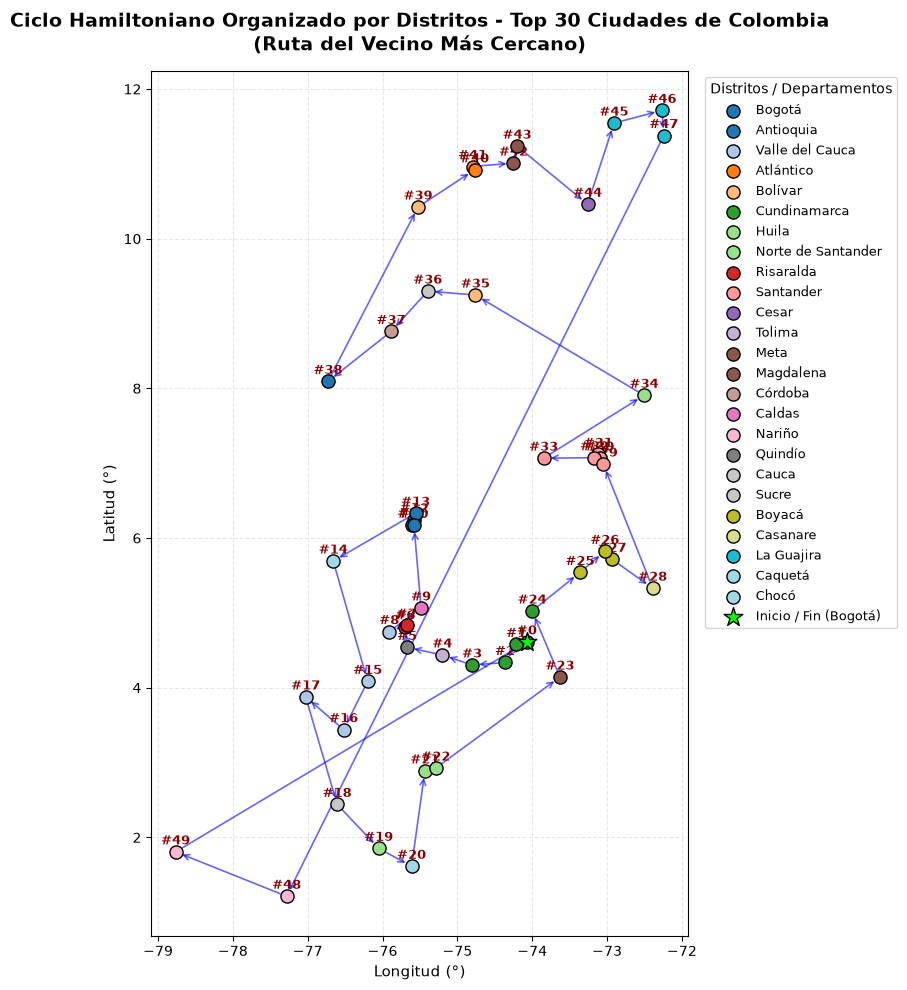

In [110]:
plt.figure(figsize=(14, 10))

for i in range(len(tour) - 1):
  u = tour[i]
  v = tour[i + 1]

  x_start, y_start = df_top.iloc[u]['lng'], df_top.iloc[u]['lat']
  x_end, y_end = df_top.iloc[v]['lng'], df_top.iloc[v]['lat']

  plt.annotate(
      '',
      xy=(x_end, y_end),
      xytext=(x_start, y_start),
      arrowprops=dict(
          arrowstyle='->', color='blue', lw=1.2, alpha=0.6, shrinkA=5, shrinkB=5
      ),
  )

distritos = df_top['admin_name'].unique()
cmap = plt.get_cmap('tab20', len(distritos))

for idx, distrito in enumerate(distritos):
  subset = df_top[df_top['admin_name'] == distrito]
  plt.scatter(
      subset['lng'],
      subset['lat'],
      color=cmap(idx),
      s=90,
      zorder=5,
      edgecolors='black',
      label=distrito,
  )

plt.scatter(
    df_top.iloc[0]['lng'],
    df_top.iloc[0]['lat'],
    color='lime',
    s=200,
    zorder=6,
    marker='*',
    edgecolors='black',
    label='Inicio / Fin (Bogotá)',
)

for step, node_idx in enumerate(tour[:-1]):
  plt.text(
      df_top.iloc[node_idx]['lng'],
      df_top.iloc[node_idx]['lat'] + 0.1,
      f'#{step}',
      fontsize=9,
      fontweight='bold',
      color='darkred',
      ha='center',
  )

plt.title(
    'Ciclo Hamiltoniano Organizado por Distritos - Top 30 Ciudades de'
    ' Colombia\n(Ruta del Vecino Más Cercano)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Longitud (°)', fontsize=11)
plt.ylabel('Latitud (°)', fontsize=11)
plt.gca().set_aspect('equal')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=9,
    title='Distritos / Departamentos',
)
plt.tight_layout()
plt.show()

Se genera un mapa detallado utilizando matplotlib, donde se trazan flechas direccionales azules para la ruta, puntos agrupados y coloreados por departamento, y números de paso para cada ciudad visitada.

In [111]:
print("="*75)
print(" ITINERARIO DETALLADO DEL CICLO HAMILTONIANO (TSP)")
print("="*75)

for i in range(len(tour) - 1):
    u = tour[i]
    v = tour[i + 1]
    
    ciudad_actual = df_top.iloc[u]['city']
    distrito_actual = df_top.iloc[u]['admin_name']
    
    ciudad_siguiente = df_top.iloc[v]['city']
    distrito_siguiente = df_top.iloc[v]['admin_name']
    
   
    tramo_dist = dist_matrix[u][v]
    
    print(f"Paso {i+1:2d}: {ciudad_actual} ({distrito_actual})  --->  {ciudad_siguiente} ({distrito_siguiente}) | Dist. tramo: {tramo_dist:.2f}")

print("="*75)
print(f" DISTANCIA TOTAL DEL RECORRIDO: {total_distance:.2f}")
print("="*75)

 ITINERARIO DETALLADO DEL CICLO HAMILTONIANO (TSP)
Paso  1: Bogotá (Bogotá)  --->  Soacha (Cundinamarca) | Dist. tramo: 0.15
Paso  2: Soacha (Cundinamarca)  --->  Fusagasugá (Cundinamarca) | Dist. tramo: 0.28
Paso  3: Fusagasugá (Cundinamarca)  --->  Girardot (Cundinamarca) | Dist. tramo: 0.44
Paso  4: Girardot (Cundinamarca)  --->  Ibagué (Tolima) | Dist. tramo: 0.42
Paso  5: Ibagué (Tolima)  --->  Armenia (Quindío) | Dist. tramo: 0.48
Paso  6: Armenia (Quindío)  --->  Pereira (Risaralda) | Dist. tramo: 0.28
Paso  7: Pereira (Risaralda)  --->  Dosquebradas (Risaralda) | Dist. tramo: 0.03
Paso  8: Dosquebradas (Risaralda)  --->  Cartago (Valle del Cauca) | Dist. tramo: 0.25
Paso  9: Cartago (Valle del Cauca)  --->  Manizales (Caldas) | Dist. tramo: 0.53
Paso 10: Manizales (Caldas)  --->  Envigado (Antioquia) | Dist. tramo: 1.11
Paso 11: Envigado (Antioquia)  --->  Itagüí (Antioquia) | Dist. tramo: 0.03
Paso 12: Itagüí (Antioquia)  --->  Medellín (Antioquia) | Dist. tramo: 0.08
Paso 13:

Se imprime paso a paso el trayecto de cada ciudad junto con su departamento correspondiente, la distancia parcial del tramo y la distancia total acumulada del ciclo hamiltoniano completado.